In [ ]:
"""
Extracting mean X, Y, Z coordinates of GPS stations from PPP (https://webapp.csrs-scrs.nrcan-rncan.gc.ca/geod/tools-outils/ppp.php) output files. 
The required output files are located in the 'PPP_outputs' folder of this repository.
Author: Hannah Picton & Andrew Tedstone
Date: 27th March 2026
"""

# Import libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import os
import pyproj

# -- PROVIDE PATH TO PPP OUTPUTS --
ppp_directory = '.../data/PPP_outputs/'

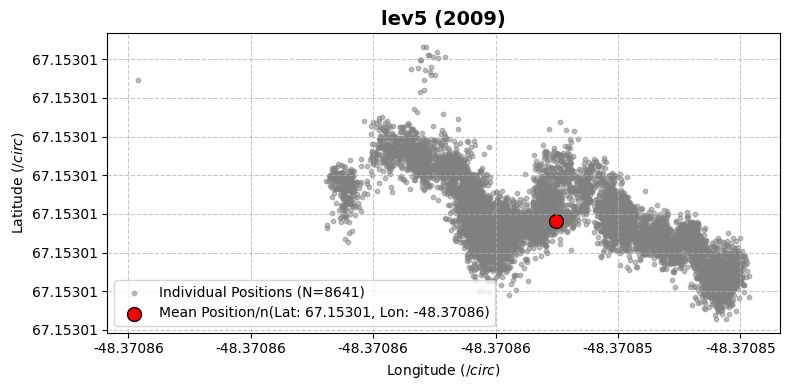

In [14]:
# --- PLOT X & Y POSITIONS FOR SPECIFIED STATION IN SPECIFIED YEAR ---

# Input desired station and year (2009 or 2021)
STATION = 'lev5'  # Choose lev5, lev6, kanu, f003, or f004
YEAR = 2009  # Choose 2009 or 2021 (note 2009 data only provided for lev5 and lev6)

def plot_single_station(base_directory, site, year):
    subdir = f'{site}_{year}'
    folder_path = os.path.join(base_directory, subdir)
    if not os.path.isdir(folder_path):
        print(f'No data available for specified year: {site.upper()} ({year})')
        return
    all_files = os.listdir(folder_path)
    csv_files = [f for f in all_files if f.endswith('.csv')]
    file_name = csv_files[0]
    file_path = os.path.join(folder_path, file_name)
    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip().str.replace('_', '')
    lat_col = [col for col in df.columns if 'latitude' in col.lower()][0]
    lon_col = [col for col in df.columns if 'longitude' in col.lower()][0]
    mean_lat = df[lat_col].mean()
    mean_lon = df[lon_col].mean()
    # --- Plot ---
    fig, ax = plt.subplots(figsize=(8, 4))
    plt.scatter(df[lon_col], df[lat_col], alpha=0.5, s=10, color='grey', label=f'Individual Positions (N={len(df)})')
    plt.scatter(mean_lon, mean_lat, alpha=1.0, s=100, color='red', marker='o', edgecolors='black', label=f'Mean Position/n(Lat: {mean_lat:.5f}, Lon: {mean_lon:.5f})')
    ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.5f'))
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.5f'))
    plt.title(f'{site} ({year})', fontweight='bold', fontsize=14)
    plt.xlabel('Longitude ($/circ$)')
    plt.ylabel('Latitude ($/circ$)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='best')
    plt.tight_layout()
    plt.show()

plot_single_station(ppp_directory, STATION, YEAR)

In [15]:
# --- PRINT MEAN POSITIONS FOR SELECTED STATIONS AND YEARS, CALCULATING HORIZONTAL DISTANCES ---
sites = ['lev5', 'lev6', 'kanu', 'f003', 'f004']
years = [2009, 2021]  # Note 2009 data only provided for lev5 and lev6

historic_positions = {
    'f003':[-46.860852, 67.179997], # Thomas et al Velocities_Data.csv
    'f004':[-47.029927, 66.918883], # Thomas et al Velocities_Data.csv
    'kanu':[-47.02, 67.00]          # Doyle 2014 page 900 at stated precision
}

def calc_dist(x1,y1,x2,y2):
    return np.sqrt((y2 - y1)**2 + (x2 - x1)**2)
pstere = pyproj.Proj('epsg:3413')

store = {}
for site in sites:
    site_store = {}
    nyr = 1
    for yr in years:
        if site in historic_positions.keys() and yr == 2009:
            x,y = pstere(*historic_positions[site])
            mean_lat, mean_lon = historic_positions[site]
        else:
                
            subdir = f'{site}_{yr}'
            folder_path = os.path.join(ppp_directory, subdir)
            if not os.path.isdir(folder_path):
                print(f'{site} ({yr}) → No data available for specified year.')
                continue
            all_files = os.listdir(folder_path)
            csv_files = [f for f in all_files if f.endswith('.csv')]
            file_name = csv_files[0]
            file_path = os.path.join(folder_path, file_name)
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip().str.replace('_', '')
            lat_col = [col for col in df.columns if 'latitude' in col.lower()][0]
            lon_col = [col for col in df.columns if 'longitude' in col.lower()][0]
            mean_lat = df[lat_col].mean()
            mean_lon = df[lon_col].mean()
            x,y = pstere(mean_lon, mean_lat)
        
        site_store[nyr] = dict(x=x, y=y)
        print(f"{site} ({nyr}) → Mean Latitude: {mean_lat:.6f}, Mean Longitude: {mean_lon:.6f}")
        nyr += 1
    store[site] = site_store

    try:
        dist = calc_dist(
            site_store[1]['x'],
            site_store[1]['y'],
            site_store[2]['x'],
            site_store[2]['y']
        )
        xdiff = site_store[2]['x'] - site_store[1]['x']
        ydiff = site_store[2]['y'] - site_store[1]['y']
        print(f"{site} hoz. distance difference: {dist:.2f} m; X: {xdiff:.2f} m, Y: {ydiff:.2f} m ")
    except KeyError:
        print('Key error, could not calculate distance')

lev5 (1) → Mean Latitude: 67.153006, Mean Longitude: -48.370855
lev5 (2) → Mean Latitude: 67.153107, Mean Longitude: -48.371630
lev5 hoz. distance difference: 35.79 m; X: -33.19 m, Y: 13.39 m 
lev6 (1) → Mean Latitude: 67.162564, Mean Longitude: -47.549155
lev6 (2) → Mean Latitude: 67.162538, Mean Longitude: -47.549356
lev6 hoz. distance difference: 9.27 m; X: -8.91 m, Y: -2.54 m 
kanu (1) → Mean Latitude: -47.020000, Mean Longitude: 67.000000
kanu (2) → Mean Latitude: 67.000440, Mean Longitude: -47.030520
kanu hoz. distance difference: 466.10 m; X: -461.41 m, Y: 65.95 m 
f003 (1) → Mean Latitude: -46.860852, Mean Longitude: 67.179997
f003 (2) → Mean Latitude: 67.180309, Mean Longitude: -46.860551
f003 hoz. distance difference: 37.47 m; X: 14.28 m, Y: 34.64 m 
f004 (1) → Mean Latitude: -47.029927, Mean Longitude: 66.918883
f004 (2) → Mean Latitude: 66.918861, Mean Longitude: -47.029835
f004 hoz. distance difference: 4.77 m; X: 3.96 m, Y: -2.66 m 


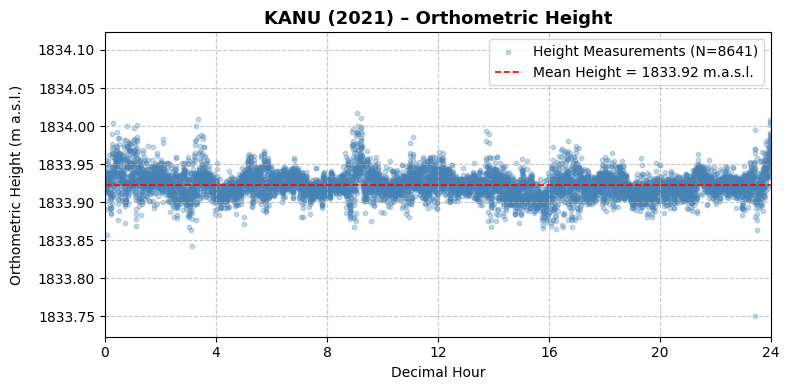

In [16]:
# --- PLOT ORTHOMETRIC HEIGHT VS DECIMAL HOUR FOR SPECIFIED STATION IN SPECIFIED YEAR ---

# Input desired station and year (2009 or 2021)
STATION = 'kanu'  # Choose lev5, lev6, kanu, f003, or f004
YEAR = 2021  # Choose 2009 or 2021 (note 2009 data only provided for lev5 and lev6)

def plot_height_time(base_directory, site, year):
    subdir = f'{site}_{year}'
    folder_path = os.path.join(base_directory, subdir)
    if not os.path.isdir(folder_path):
            print(f'{site} ({year}) → No data available for specified year.')
            return
    all_files = os.listdir(folder_path)
    csv_files = [f for f in all_files if f.endswith('.csv')]
    file_name = csv_files[0]
    file_path = os.path.join(folder_path, file_name)
    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip().str.replace('_', '')
    height_col = [col for col in df.columns if 'ortho' in col.lower()][0]
    time_col = [col for col in df.columns if 'decimalhour' in col.lower()][0]
    mean_height = df[height_col].mean()
    # --- Plot ---
    fig, ax = plt.subplots(figsize=(8, 4))
    plt.scatter(df[time_col], df[height_col], alpha=0.3, s=10, color='steelblue', label=f'Height Measurements (N={len(df)})')
    plt.axhline(mean_height, color='red', linestyle='--', linewidth=1.2, label=f'Mean Height = {mean_height:.2f} m.a.s.l.')
    plt.title(f'{site.upper()} ({year}) – Orthometric Height', fontweight='bold', fontsize=13)
    plt.xlabel('Decimal Hour')
    plt.ylabel('Orthometric Height (m a.s.l.)', labelpad=10)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.xlim(0, 24)
    plt.ylim(mean_height - 0.2, mean_height + 0.20)
    ax.ticklabel_format(style='plain', axis='y')
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
    ax.xaxis.set_major_locator(ticker.MultipleLocator(4))
    plt.legend(loc='best')
    plt.tight_layout()
    plt.show()

plot_height_time(ppp_directory, STATION, YEAR)


In [17]:
# --- PRINT MEAN ORTHOMETRIC HEIGHT FOR SELECTED STATIONS AND YEARS ---
sites = ['lev5', 'lev6', 'kanu', 'f003', 'f004']
years = [2009, 2021]  # Note 2009 data only provided for lev5 and lev6

for site in sites:
    for yr in years:
        subdir = f'{site}_{yr}'
        folder_path = os.path.join(ppp_directory, subdir)
        if not os.path.isdir(folder_path):
            print(f'{site} ({yr}) → No data available for specified year.')
            continue
        all_files = os.listdir(folder_path)
        csv_files = [f for f in all_files if f.endswith('.csv')]
        file_name = csv_files[0]
        file_path = os.path.join(folder_path, file_name)

        df = pd.read_csv(file_path)
        df.columns = df.columns.str.strip().str.replace('_', '')

        height_col = [col for col in df.columns if 'ortho' in col.lower()][0]
        mean_height = df[height_col].mean()

        print(f"{site.upper()} ({yr}) → Mean Orthometric Height: {mean_height:.3f} m.a.s.l.")

LEV5 (2009) → Mean Orthometric Height: 1445.046 m.a.s.l.
LEV5 (2021) → Mean Orthometric Height: 1439.612 m.a.s.l.
LEV6 (2009) → Mean Orthometric Height: 1674.595 m.a.s.l.
LEV6 (2021) → Mean Orthometric Height: 1673.426 m.a.s.l.
kanu (2009) → No data available for specified year.
KANU (2021) → Mean Orthometric Height: 1833.923 m.a.s.l.
f003 (2009) → No data available for specified year.
F003 (2021) → Mean Orthometric Height: 1869.792 m.a.s.l.
f004 (2009) → No data available for specified year.
F004 (2021) → Mean Orthometric Height: 1837.399 m.a.s.l.


In [18]:
# --- PRINT MEAN SDHGT(95%) FOR SELECTED STATIONS AND YEARS (BASED ON .POS FILES) ---
target_sites = ['lev5', 'lev6'] # Not required for all stations; only lev5 and lev6 included in repository.
target_years = [2009, 2021]
all_results = {}

print(f"{'Site (Year)':<18} | {'Direction':<10} | {'Mean SDHGT (95%)':<20}")
print("-" * 60)
for site in target_sites:
    for yr in target_years:
        subdir = f"{site}_{yr}"
        folder_path = os.path.join(ppp_directory, subdir)
        if not os.path.isdir(folder_path): 
            continue
        pos_files = [f for f in os.listdir(folder_path) if f.endswith('.pos')]
        if not pos_files: 
            continue
        file_path = os.path.join(folder_path, pos_files[0])
        data_rows = []
        header = None
        found_directions = set()
        with open(file_path, 'r') as f:
            for line in f:
                if line.startswith(('/', '*', ' ')) or not line.strip(): 
                    continue
                if line.startswith('DIR'):
                    header = line.split()
                    continue
                if header:
                    row = line.split()
                    if row: 
                        found_directions.add(row[0])
                        # NRCan uses 'FIN' for modern files, 'BWD' for older ones
                        if row[0] in ['FIN', 'BWD']:
                            data_rows.append(row)
        if data_rows:
            df = pd.DataFrame(data_rows, columns=header)
            # Choose 'FIN' if available, otherwise 'BWD'
            final_dir = 'FIN' if 'FIN' in df['DIR'].values else 'BWD'
            subset = df[df['DIR'] == final_dir]
            # Convert error column to numeric and calculate mean
            errors = pd.to_numeric(subset['SDHGT(95%)'], errors='coerce').dropna()
            mean_val = errors.mean()
            label = f"{site.upper()} ({yr})"
            all_results[label] = mean_val
            print(f"{label:<18} | {final_dir:<10} | {mean_val:.4f} meters")
        else:
            label = f"{site.upper()} ({yr})"
            print(f"{label:<18} | NO FIN/BWD | Tags found: {found_directions}")

if all_results:
    mean = np.mean(list(all_results.values()))
    print("-" * 60)
    print(f"{'MEAN':<31} | {mean:.4f} meters")

Site (Year)        | Direction  | Mean SDHGT (95%)    
------------------------------------------------------------
LEV5 (2009)        | BWD        | 0.0793 meters
LEV5 (2021)        | FIN        | 0.0724 meters
LEV6 (2009)        | BWD        | 0.0786 meters
LEV6 (2021)        | FIN        | 0.0779 meters
------------------------------------------------------------
MEAN                            | 0.0770 meters
